# 03 — Folds and naive baselines

Defines the rolling-origin folds and scores the **naive baselines** — the numbers every later model has to beat. No model is fitted here, and **the locked 2021–2025 test set is never scored in this notebook.**

**Target:** log(1 + state-based deaths) `HORIZON` months after the origin month *t* (default 1). All errors are on that log scale.

| Baseline | Prediction for month *t* + h |
|---|---|
| Zero | log(1 + 0) = 0 — "no conflict anywhere" |
| Persistence | this month's log(1 + deaths) |
| Mean of last 3 | average of the last 3 months' log(1 + deaths) |
| Mean of last 12 | average of the last 12 months' log(1 + deaths) |

All four use only information available at month *t*.

**Folds** split on the *target* month, so no training target ever falls inside a validation window (reasoning in `Planning/ML FP Progress Log.md`, 2026-10-01).

**Reading the results.** About 85% of rows are quiet-to-quiet, where every baseline is nearly perfect. The informative columns are the *onset* and *continuation* rows, split out below.

## Setup

In [1]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.paths import PROCESSED
from src.eval.splits import FOLDS, TEST, make_supervised, fold_masks
from src.eval.metrics import rmse, mae, score, transition_type

HORIZON = 1          # months ahead; change and re-run (section 5 sweeps 1, 3, 6, 12)
CONFLICT_MIN = 1.0   # a "conflict month" has >= 1 state-based death

pd.set_option("display.width", 140, "display.max_columns", 30)
BASELINES = ["zero", "persistence", "mean of last 3", "mean of last 12"]
COLORS = dict(zip(BASELINES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))  # fixed order
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Load the panel and build the supervised table

One row per (state, origin month *t*). `y` is the target at *t* + `HORIZON`. The baseline predictions are added as columns from each state's own history (rolling windows run **within** a state and end at *t*).

In [2]:
panel = pd.read_parquet(PROCESSED / "panel_base.parquet")
panel = panel.sort_values(["gwno", "month"], ignore_index=True)

# History-only baseline inputs, computed inside each state and ending at the origin month t.
panel["log_sb"] = np.log1p(panel["sb_best"])
g = panel.groupby("gwno")["log_sb"]
panel["pred_zero"] = 0.0
panel["pred_persistence"] = panel["log_sb"]
panel["pred_mean of last 3"] = g.transform(lambda s: s.rolling(3, min_periods=1).mean())
panel["pred_mean of last 12"] = g.transform(lambda s: s.rolling(12, min_periods=1).mean())
panel["now_conflict"] = panel["sb_best"] >= CONFLICT_MIN

df = make_supervised(panel, horizon=HORIZON)
df["next_conflict"] = df["raw_y"] >= CONFLICT_MIN
df["kind"] = transition_type(df["now_conflict"], df["next_conflict"])

print(f"Supervised rows (horizon {HORIZON}): {len(df):,}")
print(f"Target months: {df['target_month'].min():%Y-%m} … {df['target_month'].max():%Y-%m}")

Supervised rows (horizon 1): 75,525
Target months: 1989-02 … 2025-12


## 2. The folds

Each fold trains on every target up to `train_end` and validates on the next three years. The final row is the locked test: its rows are counted for planning but **never scored here**.

In [3]:
rows = []
for f in FOLDS:
    tr, va = fold_masks(df, f)
    rows.append({"fold": f.name, "train targets": f"1989-02 … {f.train_end:%Y-%m}",
                 "validate on": f"{f.val_start:%Y-%m} … {f.val_end:%Y-%m}",
                 "train rows": int(tr.sum()), "validation rows": int(va.sum()),
                 "validation onsets": int((df.loc[va, "kind"] == "onset").sum()),
                 "validation conflict rows": int(df.loc[va, "now_conflict"].sum())})
te = (df["target_month"] >= TEST.val_start) & (df["target_month"] <= TEST.val_end)
rows.append({"fold": TEST.name, "train targets": f"1989-02 … {TEST.train_end:%Y-%m}",
             "validate on": f"{TEST.val_start:%Y-%m} … {TEST.val_end:%Y-%m}",
             "train rows": int((df['target_month'] <= TEST.train_end).sum()),
             "validation rows": int(te.sum()), "validation onsets": int((df.loc[te, "kind"] == "onset").sum()),
             "validation conflict rows": int(df.loc[te, "now_conflict"].sum())})
folds_table = pd.DataFrame(rows).set_index("fold")
display(folds_table)
print("'onset' here = quiet this month, conflict next month (the simple version; the final k/m definition is still open).")
del te   # the test mask is not used again in this notebook

,train targets,validate on,train rows,validation rows,validation onsets,validation conflict rows
fold,,,,,,
fold 1,1989-02 … 2005-12,2006-01 … 2008-12,33864,6196,115,792
fold 2,1989-02 … 2008-12,2009-01 … 2011-12,40060,6233,108,781
fold 3,1989-02 … 2011-12,2012-01 … 2014-12,46293,6264,119,872
fold 4,1989-02 … 2014-12,2015-01 … 2017-12,52557,6264,163,1068
fold 5,1989-02 … 2017-12,2018-01 … 2020-12,58821,6264,166,1098
TEST (locked),1989-02 … 2020-12,2021-01 … 2025-12,65085,10440,212,1896


'onset' here = quiet this month, conflict next month (the simple version; the final k/m definition is still open).


## 3. Baseline scores on the five validation folds

Rows in `all rows` are dominated by quiet-to-quiet months, so look at the other four labels: a model that cannot beat persistence on *onset* and *continuation* rows has learned nothing beyond "things stay as they are".

In [4]:
records = []
for f in FOLDS:
    _, va = fold_masks(df, f)
    sub = df[va]
    for b in BASELINES:
        s = score(sub["y"], sub[f"pred_{b}"], sub["kind"]).reset_index(names="subset")
        s.insert(0, "baseline", b); s.insert(0, "fold", f.name)
        records.append(s)
scores = pd.concat(records, ignore_index=True)

# Pooled over folds 1-5 (every validation row weighted equally)
val_all = pd.concat([df[fold_masks(df, f)[1]].assign(fold=f.name) for f in FOLDS], ignore_index=True)
pooled = pd.concat([
    score(val_all["y"], val_all[f"pred_{b}"], val_all["kind"]).reset_index(names="subset").assign(baseline=b)
    for b in BASELINES])
print(f"Pooled over folds 1–5 ({len(val_all):,} validation rows, targets 2006–2020):")
display(pooled.pivot(index="baseline", columns="subset", values="RMSE")
        .reindex(BASELINES)[["all rows", "stay quiet", "onset", "continuation", "cessation"]].round(3))
print("Row counts:", pooled[pooled['baseline'] == 'zero'].set_index('subset')['n'].astype(int).to_dict())

Pooled over folds 1–5 (31,221 validation rows, targets 2006–2020):


subset,all rows,stay quiet,onset,continuation,cessation
baseline,,,,,
zero,1.468,0.012,2.286,4.022,0.087
persistence,0.583,0.006,2.271,1.030,2.107
mean of last 3,0.527,0.146,1.853,1.008,1.643
mean of last 12,0.552,0.204,1.665,1.138,1.481


Row counts: {'all rows': 31221, 'stay quiet': 25939, 'onset': 671, 'continuation': 3945, 'cessation': 666}


In [5]:
# Mean and spread of the per-fold RMSE (the headline numbers later models are compared with)
per_fold = scores[scores["subset"] == "all rows"].pivot(index="baseline", columns="fold", values="RMSE").reindex(BASELINES)
per_fold["mean"] = per_fold.mean(axis=1); per_fold["std"] = per_fold.iloc[:, :5].std(axis=1)
print("RMSE on all validation rows, per fold:")
display(per_fold.round(3))

per_fold_mae = scores[scores["subset"] == "all rows"].pivot(index="baseline", columns="fold", values="MAE").reindex(BASELINES)
per_fold_mae["mean"] = per_fold_mae.mean(axis=1)
print("MAE on all validation rows, per fold:")
display(per_fold_mae.round(3))

RMSE on all validation rows, per fold:


fold,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
baseline,,,,,,,
zero,1.289,1.326,1.511,1.638,1.545,1.462,0.149
persistence,0.576,0.534,0.560,0.644,0.593,0.582,0.041
mean of last 3,0.526,0.491,0.508,0.574,0.532,0.526,0.031
mean of last 12,0.542,0.539,0.560,0.576,0.541,0.552,0.016


MAE on all validation rows, per fold:


fold,fold 1,fold 2,fold 3,fold 4,fold 5,mean
baseline,,,,,,
zero,0.413,0.422,0.495,0.588,0.570,0.497
persistence,0.156,0.143,0.158,0.209,0.191,0.171
mean of last 3,0.151,0.138,0.151,0.196,0.180,0.163
mean of last 12,0.163,0.161,0.171,0.208,0.190,0.179


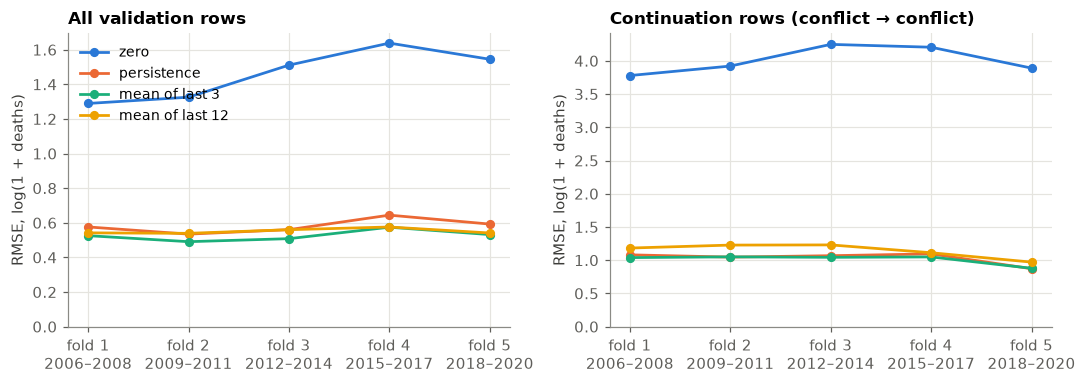

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, subset, title in [(axes[0], "all rows", "All validation rows"),
                          (axes[1], "continuation", "Continuation rows (conflict → conflict)")]:
    t = scores[scores["subset"] == subset].pivot(index="fold", columns="baseline", values="RMSE")[BASELINES]
    for b in BASELINES:
        ax.plot(range(1, 6), t[b].to_numpy(), marker="o", markersize=5, color=COLORS[b], label=b)
    ax.set_xticks(range(1, 6), [f"fold {i}\n{FOLDS[i-1].val_start.year}–{FOLDS[i-1].val_end.year}" for i in range(1, 6)])
    ax.set_title(title); ax.set_ylabel("RMSE, log(1 + deaths)"); ax.set_ylim(0, None)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 4. Where persistence fails

Persistence is exactly wrong on two kinds of row: it predicts conflict for **cessations** and predicts nothing for **onsets**. The table counts how often each happens and how large the miss is. This is the room a model has to add value.

In [7]:
kinds = ["stay quiet", "onset", "continuation", "cessation"]
tab = (val_all.groupby("kind")
       .agg(rows=("y", "size"), mean_target=("y", "mean"), mean_persistence=("pred_persistence", "mean"))
       .reindex(kinds))
tab["share of rows"] = (tab["rows"] / tab["rows"].sum()).map("{:.1%}".format)
tab["mean abs miss (persistence)"] = [
    mae(val_all.loc[val_all.kind == k, "y"], val_all.loc[val_all.kind == k, "pred_persistence"]) for k in kinds]
display(tab.round(3))

# Share of total squared error each row type carries
se = (val_all["y"] - val_all["pred_persistence"]) ** 2
share = se.groupby(val_all["kind"]).sum().reindex(kinds) / se.sum()
print("Share of persistence's total squared error, by row type:")
display((share * 100).round(1).map("{:.1f}%".format).to_frame("share"))

,rows,mean_target,mean_persistence,share of rows,mean abs miss (persistence)
kind,,,,,
stay quiet,25939,0.000,0.000,83.1%,0.000
onset,671,1.941,0.014,2.1%,1.927
continuation,3945,3.604,3.619,12.6%,0.723
cessation,666,0.015,1.821,2.1%,1.806


Share of persistence's total squared error, by row type:


,share
kind,
stay quiet,0.0%
onset,32.6%
continuation,39.5%
cessation,27.9%


## 5. How fast does the baseline decay with the horizon?

Persistence is strongest at one month and weakens as the horizon grows; a model with memory should hold up better. This sweep pools folds 1–5 at each horizon. Relative skill is `1 − RMSE / RMSE(zero)`, so higher is better and 0 means no better than predicting zero.

In [8]:
rows = []
for h in [1, 3, 6, 12]:
    dh = make_supervised(panel, horizon=h)
    mask = pd.concat([fold_masks(dh, f)[1] for f in FOLDS], axis=1).any(axis=1)
    v = dh[mask]
    r = {"horizon (months)": h, "rows": len(v)}
    for b in BASELINES:
        r[f"RMSE {b}"] = rmse(v["y"], v[f"pred_{b}"])
    r["skill: persistence"] = 1 - r["RMSE persistence"] / r["RMSE zero"]
    r["skill: mean of last 12"] = 1 - r["RMSE mean of last 12"] / r["RMSE zero"]
    rows.append(r)
sweep = pd.DataFrame(rows).set_index("horizon (months)")
display(sweep.round(3))
print("Fold windows are defined on the target month, so at longer horizons the origin months are earlier.")

,rows,RMSE zero,RMSE persistence,RMSE mean of last 3,RMSE mean of last 12,skill: persistence,skill: mean of last 12
horizon (months),,,,,,,
1,31221,1.468,0.583,0.527,0.552,0.603,0.624
3,31213,1.468,0.669,0.599,0.592,0.545,0.597
6,31201,1.468,0.725,0.650,0.636,0.506,0.567
12,31177,1.468,0.777,0.713,0.708,0.471,0.518


Fold windows are defined on the target month, so at longer horizons the origin months are earlier.


## 6. Summary — what a model has to beat

Results of the first run (horizon 1, folds 1–5, RMSE on log(1 + deaths), mean of the five per-fold RMSEs):

| Baseline | RMSE | Beats persistence in |
|---|---|---|
| Zero | 1.462 | 0 of 5 folds |
| Persistence | 0.582 | — |
| **Mean of last 3 months** | **0.526** | **5 of 5 folds** |
| Mean of last 12 months | 0.552 | 5 of 5 folds |

- **The strongest naive baseline is the 3-month mean, not persistence.** It is the number to beat at horizon 1; at horizons of 3 months and longer the 12-month mean takes over (section 5). A model that only beats persistence has not shown much.
- **All of the error sits in 17% of rows.** Quiet-to-quiet rows (83%) carry essentially none. Persistence's squared error splits roughly one-third onsets, two-fifths continuations, one-quarter cessations.
- **Onsets are essentially unpredictable for all four baselines** (RMSE 1.7–2.3 against a mean target of 1.9 log units). This is where a model can add the most.
- **Skill decays slowly with horizon:** persistence goes from 0.60 at one month to 0.47 at twelve.

**Cautions that apply to every number here**
- Year-long GED events become flat plateaus after spreading deaths across days, which makes persistence look slightly better than it would on cleanly dated events.
- Errors are on the log scale. Raw-death errors would be dominated by Ethiopia 2021–22 and Ukraine 2022, which fall in the locked test period.
- `onset` here is the simple quiet → conflict transition, not the final onset definition.
- The final months of GED 26.1 (Nov–Dec 2025) have noticeably fewer recorded events than the 2025 average (about −23% and −14% for state-based; −38% for one-sided in December). These months fall in the locked test window; consider reporting the test result with and without them.